# Audios reales y BigVSAN: dataset por persona

Genera `artifacts/old_vowels_dataset/` en las dos modalidades: **audio** y **espectrograma log-mel**. Cada persona conserva exactamente el `split` y `cv_fold` de `artifacts/vowels_dataset/people.csv`, incluidos sus audios reales y las variantes generadas que se conservan en train y val.

Se mantienen 70 personas en train, 10 en val y 20 en test, con equilibrio de clases. Los cinco folds se forman exclusivamente dentro de train: 56 personas para entrenamiento y 14 para validación interna. `val.csv` es la validación global de desarrollo; `test.csv` es el test global final.

Las fuentes contienen únicamente la vocal A, tres repeticiones reales por persona y hasta 40 variantes generadas por repetición. Los audios se conservan a **0,48 s, 24 kHz, mono PCM16**, sin recorte, relleno ni remuestreo.

**Hemos quitado los 2.399 generados de las personas de test** (1.200 control + 1.199 patológicos). No se trasladan a train ni a val. Test contiene únicamente 60 audios reales de 20 personas (30 audios por clase). El dataset final conserva 9.899 audios (300 reales + 9.599 generados).

## 1. Parámetros y fuentes

Requiere NumPy, pandas, SciPy y Matplotlib. Ejecutar primero `vowels_dataset_por_persona.ipynb` si falta su `people.csv`. La implementación compartida está en `scripts/prepare_old_vowels_dataset.py`.

Solo se leen las cuatro carpetas nombradas en `SOURCE_FOLDERS`; los ficheros AppleDouble de `__MACOSX` se registran y excluyen. Se conservan los generados de train y val; los generados de test se descartan del dataset exportado. Los originales se conservan en las carpetas de origen. Un fichero generado nunca se trata como una persona nueva.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'scripts' / 'prepare_old_vowels_dataset.py').is_file():
    raise RuntimeError('Ejecutar desde la raíz del repositorio')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts.prepare_old_vowels_dataset import (
    SOURCE_FOLDERS, inventory, assign_reference_splits, exclude_generated_test, distribution, prepare,
)
SOURCE_ROOT = PROJECT_ROOT / 'old_data_do_not_use'
OUTPUT_ROOT = PROJECT_ROOT / 'artifacts' / 'old_vowels_dataset'
REFERENCE_PEOPLE = PROJECT_ROOT / 'artifacts' / 'vowels_dataset' / 'people.csv'
print('Salida:', OUTPUT_ROOT)
display(pd.DataFrame.from_dict(SOURCE_FOLDERS, orient='index', columns=['clase', 'origen']))

Salida: G:\Neuroevolution-ipynbs\artifacts\old_vowels_dataset


,clase,origen
control_files_short_24khz,Control,real
pathological_files_short_24khz,Patologicas,real
pretrained_40_1e5_BigVSAN_generated_control,Control,generated
pretrained_40_1e5_BigVSAN_generated_pathological,Patologicas,generated


## 2. Inventario y asignación por persona

El identificador incluye la clase (`Control_NNNN` o `Patologicas_NNNN`). El nombre del generado permite localizar su audio real de origen. Se validan etiquetas, repeticiones, frecuencia, duración y correspondencia con las personas del dataset de referencia. Las variantes ausentes se enumeran sin inventar ni duplicar datos.

Después de asignar personas y folds, se quitan únicamente los generados de test. Train, val y los cinco folds conservan las mismas personas y grabaciones.

In [2]:
raw_manifest, source_audit = inventory(SOURCE_ROOT)
manifest, people = assign_reference_splits(raw_manifest, REFERENCE_PEOPLE)
manifest, people, excluded_test_generated = exclude_generated_test(manifest, people)
print("Generados quitados de test:", len(excluded_test_generated))
display(excluded_test_generated.groupby("label").size().rename("quitados").to_frame())
print(f'{len(manifest):,} audios; {len(people)} personas')
print('Ficheros auxiliares de macOS excluidos:', len(source_audit['ignored_metadata_files']))
display(pd.DataFrame(source_audit['missing_generated_variants']))
display(distribution(manifest).query("partition in ['train', 'val', 'test']"))

Generados quitados de test: 2399


,quitados
label,
Control,1200
Patologicas,1199


9,899 audios; 100 personas
Ficheros auxiliares de macOS excluidos: 300


,source_audio_id,generation_iteration
0,AVPEPUDEA0045a2_shortened,31
1,AVPEPUDEAC0050a2_shortened,11


,partition,label,origin,people,audios
0,train,Control,generated,35,4199
1,train,Control,real,35,105
2,train,Patologicas,generated,35,4200
3,train,Patologicas,real,35,105
4,val,Control,generated,5,600
5,val,Control,real,5,15
6,val,Patologicas,generated,5,600
7,val,Patologicas,real,5,15
8,test,Control,real,10,30
9,test,Patologicas,real,10,30


## 3. Generación de WAV, representaciones y arrays

- `npy_audio/`: onda `float32`, PCM16 / 32768, forma `(1, 11520)`.
- `npy/`: log-mel `float32`, forma `(64, 44)`, 64 bandas, FFT 1024, salto 240 muestras (10 ms), rango 80–8000 Hz y `log1p(1000 * mel_power)`. La transformación es la misma que en vowels, con el salto adaptado a 24 kHz.
- `arrays_audio/` y `arrays/`: arrays globales de train, val y test, y train/val internos de los cinco folds. Los nombres usan `old_vowels` como dataset ID.

Los CSV y las dos modalidades comparten exactamente el orden de grabaciones y etiquetas. Los CSV numeran folds 0–4; los arrays los numeran 1–5, como el notebook de referencia. La generación verifica todos los WAV y cada fila de los arrays en ambas modalidades. Puede volver a ejecutarse sobre su propio directorio de salida.

Al volver a ejecutar el cuaderno, también se quitan las salidas antiguas de esos generados en `test/`, `npy_audio/test/` y `npy/test/`. Los arrays y CSV de test se reconstruyen con los 60 audios reales.

In [3]:
verification = prepare(SOURCE_ROOT, OUTPUT_ROOT, REFERENCE_PEOPLE)
display(pd.Series(verification, name='resultado').to_frame())

   partition       label    origin  people  audios
       train     Control generated      35    4199
       train     Control      real      35     105
       train Patologicas generated      35    4200
       train Patologicas      real      35     105
         val     Control generated       5     600
         val     Control      real       5      15
         val Patologicas generated       5     600
         val Patologicas      real       5      15
        test     Control      real      10      30
        test Patologicas      real      10      30
fold_0_train     Control generated      28    3359
fold_0_train     Control      real      28      84


Recordings: 1000/9899


Recordings: 2000/9899


Recordings: 3000/9899


Recordings: 4000/9899


...

Verified fold_3_val.csv: 1722 recordings


Verified fold_4_train.csv: 6887 recordings


Verified fold_4_val.csv: 1722 recordings


{
  "verified": true,
  "people": 100,
  "audios": 9899,
  "real_audios": 300,
  "generated_audios": 9599,
  "test_real_audios": 60,
  "test_generated_audios": 0,
  "excluded_test_generated_audios": 2399,
  "person_leakage": false,
  "num_folds": 5,
  "audio_shape": [
    1,
    11520
  ],
  "spectrogram_shape": [
    64,
    44
  ],
  "array_csv_alignment": "all rows in both modalities and all partitions checked"
}


,resultado
verified,True
people,100
audios,9899
real_audios,300
generated_audios,9599
test_real_audios,60
test_generated_audios,0
excluded_test_generated_audios,2399
person_leakage,False
num_folds,5


## 4. Distribución obtenida

El reparto se hace por persona, no por archivo. Test solo incluye los reales; la barra de generados en test es cero. Por eso, la variante ausente de train puede causar una diferencia mínima en los recuentos de generados conservados, aunque el número de personas por clase sea exactamente equilibrado.

,partition,label,origin,people,audios
0,train,Control,generated,35,4199
1,train,Control,real,35,105
2,train,Patologicas,generated,35,4200
3,train,Patologicas,real,35,105
4,val,Control,generated,5,600
5,val,Control,real,5,15
6,val,Patologicas,generated,5,600
7,val,Patologicas,real,5,15
8,test,Control,real,10,30
9,test,Patologicas,real,10,30


,partition,label,origin,people,audios
10,fold_0_train,Control,generated,28,3359
11,fold_0_train,Control,real,28,84
12,fold_0_train,Patologicas,generated,28,3360
13,fold_0_train,Patologicas,real,28,84
14,fold_0_val,Control,generated,7,840
15,fold_0_val,Control,real,7,21
16,fold_0_val,Patologicas,generated,7,840
17,fold_0_val,Patologicas,real,7,21
18,fold_1_train,Control,generated,28,3359
19,fold_1_train,Control,real,28,84


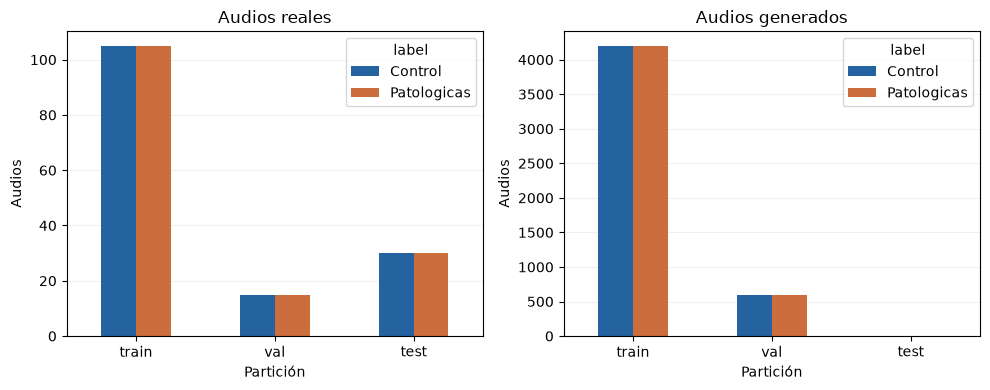

In [4]:
summary = pd.read_csv(OUTPUT_ROOT / 'distribution.csv')
global_summary = summary.loc[summary.partition.isin(['train', 'val', 'test'])]
display(global_summary)
display(summary.loc[summary.partition.str.contains('fold_')])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, origin, title in zip(axes, ['real', 'generated'], ['Audios reales', 'Audios generados']):
    values = global_summary.loc[global_summary.origin.eq(origin)].pivot(index='partition', columns='label', values='audios').reindex(['train', 'val', 'test']).fillna(0)
    values.plot.bar(ax=ax, color=['#2463a0', '#cb6d3d'], rot=0)
    ax.set(title=title, xlabel='Partición', ylabel='Audios')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 5. Comprobaciones y uso

`verification.json` registra las comprobaciones completas; `source_audit.json` enumera variantes ausentes, metadatos excluidos y recuentos de los generados quitados de test; `excluded_test_generated.csv` lista los 2.399 audios quitados con sus rutas originales; `dataset_config.json` guarda fuentes y la huella SHA-256 del reparto de referencia. `manifest.csv` incluye el SHA-256 de cada fuente, la persona, el origen, la iteración y las rutas a las dos representaciones.

Para cargar este dataset: `data_path = artifacts/old_vowels_dataset`, `dataset_id = old_vowels`, `num_folds = 5`. En audio: `fold_files_subdirectory = arrays_audio`, `num_channels = 1`, `sequence_length = 11520`. En espectrograma: `fold_files_subdirectory = arrays`, `num_channels = 1`, `num_frequency_bins = 64`, `sequence_length = 44`. Los campos `evolution_*` y `final_*` deben apuntar al mismo dataset y directorio de la modalidad elegida; `audio_sample_rate_hz = 24000` y `audio_duration_s = 0.48`.

El experimento configurado actualmente no se cambia automáticamente. Esta separación impide compartir personas entre particiones; las carpetas no documentan qué personas se usaron para entrenar BigVSAN, por lo que no permite verificar la independencia del entrenamiento del generador.

In [5]:
saved_people = pd.read_csv(OUTPUT_ROOT / 'people.csv', dtype={'cv_fold': 'Int64'})
reference = pd.read_csv(REFERENCE_PEOPLE, dtype={'cv_fold': 'Int64'})
columns = ['person_id', 'label', 'label_binary', 'split', 'cv_fold']
pd.testing.assert_frame_equal(
    saved_people[columns].sort_values('person_id').reset_index(drop=True),
    reference[columns].sort_values('person_id').reset_index(drop=True),
)
assert verification['verified'] and not verification['person_leakage']
print('Reparto idéntico a vowels_dataset; ambas modalidades verificadas.')

saved_manifest = pd.read_csv(OUTPUT_ROOT / "manifest.csv")
test_rows = saved_manifest.loc[saved_manifest.split.eq("test")]
assert len(test_rows) == 60 and test_rows.origin.eq("real").all()
assert verification["test_generated_audios"] == 0
assert verification["excluded_test_generated_audios"] == 2399
assert saved_people.loc[saved_people.split.eq("test"), "generated_audios"].eq(0).all()
print("Test: 60 reales; hemos quitado sus 2.399 generados de ambas modalidades.")

Reparto idéntico a vowels_dataset; ambas modalidades verificadas.
Test: 60 reales; hemos quitado sus 2.399 generados de ambas modalidades.
